# Latent Semantic Analysis and the Singular Value Decomposition

### From matrix factorization to topic detection and text summarization

---

**Abstract.** This notebook develops Latent Semantic Analysis (LSA) from its linear-algebraic
foundation — the Singular Value Decomposition (SVD) — and applies it to two classic
Natural Language Processing tasks: **unsupervised topic detection** and **extractive text
summarization**. We work throughout on a real corpus (2,225 BBC News articles spanning five
categories), so that every plot and metric reported below is reproducible end to end.

**Contents**

1. [Motivation: representing text as vectors](#1)
2. [The Singular Value Decomposition](#2)
3. [From SVD to Latent Semantic Analysis](#3)
4. [Data and experimental setup](#4)
5. [Building the term–document matrix](#5)
6. [Applying truncated SVD](#6)
7. [Interpreting the latent concepts](#7)
8. [Visualizing the semantic space](#8)
9. [Application I — Unsupervised topic detection](#9)
10. [Application II — Extractive text summarization with LSA](#10)
11. [Discussion, limitations, and further reading](#11)


## 1. Motivation: representing text as vectors <a id="1"></a>

The classical **Vector Space Model** (Salton, 1975) represents a corpus of $n$ documents over
a vocabulary of $m$ terms as a term–document matrix $A \in \mathbb{R}^{m \times n}$, where each
entry $A_{ij}$ measures the importance of term $i$ in document $j$ (typically a TF‑IDF weight,
introduced in Section 5). Two documents are then compared geometrically, e.g. via the cosine
of the angle between their column vectors.

This "bag-of-words" representation is simple and effective, but it suffers from two
well-known linguistic problems:

- **Synonymy** — different words with the same meaning ("car", "automobile") are treated as
  unrelated dimensions, so documents that are conceptually similar but lexically different get
  an artificially low similarity score.
- **Polysemy** — the same word can carry different meanings depending on context ("bank" as a
  financial institution vs. a riverbank), which pollutes a term's vector representation.

$A$ is also extremely **sparse** and **high-dimensional**: a vocabulary of a few thousand
words means every document is a point in a space with a few thousand axes, most of them zero.

**Latent Semantic Analysis** (Deerwester, Dumais, Furnas, Landauer & Harshman, 1990) addresses
both problems at once with a single idea: apply a low-rank matrix approximation to $A$ so that
terms and documents are re-expressed in a much smaller space of **latent concepts** — linear
combinations of co-occurring terms — rather than in the space of raw vocabulary. Two documents
that share few exact words but many concepts will be pulled close together in this new space.
The tool that makes this possible is the Singular Value Decomposition.

## 2. The Singular Value Decomposition <a id="2"></a>

### 2.1 Definition

Every real matrix $A \in \mathbb{R}^{m \times n}$ of rank $r$ admits a factorization

$$
A = U \, \Sigma \, V^{T}
$$

where

- $U \in \mathbb{R}^{m \times m}$ is **orthogonal**: its columns $u_1, \dots, u_m$ (the *left
  singular vectors*) form an orthonormal basis of the term space $\mathbb{R}^m$;
- $V \in \mathbb{R}^{n \times n}$ is **orthogonal**: its columns $v_1, \dots, v_n$ (the *right
  singular vectors*) form an orthonormal basis of the document space $\mathbb{R}^n$;
- $\Sigma \in \mathbb{R}^{m \times n}$ is **diagonal** (in the generalized sense), with
  non-negative entries $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r > 0$ on the diagonal — the
  **singular values** of $A$ — and zeros elsewhere.

Equivalently, $A$ can be written as a sum of $r$ rank-1 matrices, ordered by importance:

$$
A = \sum_{k=1}^{r} \sigma_k \, u_k v_k^{T}.
$$

### 2.2 Relationship to eigen-decomposition

The singular values and vectors of $A$ are obtained from the eigen-decompositions of the two
(symmetric, positive semi-definite) Gram matrices built from $A$:

$$
A^{T}A = V \Sigma^{T}\Sigma \, V^{T}, \qquad A A^{T} = U \Sigma \Sigma^{T} U^{T}.
$$

So $v_k$ is an eigenvector of $A^T A$ (the term-term co-occurrence matrix restricted to
documents), $u_k$ is an eigenvector of $A A^T$ (the document-document co-occurrence matrix
restricted to terms), and $\sigma_k = \sqrt{\lambda_k}$ where $\lambda_k$ is the corresponding
eigenvalue, shared by both matrices. This is also why SVD generalizes Principal Component
Analysis: PCA is exactly the SVD of a (mean-centered) data matrix.

### 2.3 Truncated SVD and the Eckart–Young theorem

Keeping only the $k$ largest singular values and corresponding vectors gives the **truncated
SVD**

$$
A_k = U_k \, \Sigma_k \, V_k^{T} = \sum_{i=1}^{k} \sigma_i \, u_i v_i^{T}, \qquad k < r.
$$

The **Eckart–Young theorem** states that $A_k$ is the *best possible* rank-$k$ approximation of
$A$ under both the Frobenius norm and the spectral norm:

$$
A_k = \underset{\text{rank}(B) \le k}{\arg\min} \; \lVert A - B \rVert_F .
$$

In other words, no other rank-$k$ matrix reconstructs $A$ more faithfully. This optimality
guarantee is the mathematical justification for why truncating the SVD is a principled way to
compress a matrix, rather than an arbitrary heuristic — and it is exactly what
`sklearn.decomposition.TruncatedSVD` computes.

## 3. From SVD to Latent Semantic Analysis <a id="3"></a>

Applying truncated SVD to a term–document matrix $A$ ($m$ terms, $n$ documents) with a chosen
number of concepts $k \ll \min(m, n)$ yields three factors that have a direct linguistic
reading:

| Factor | Shape | Interpretation |
|---|---|---|
| $U_k$ | $m \times k$ | Each row is a **term** expressed as a mixture of $k$ latent concepts. |
| $\Sigma_k$ | $k \times k$ | The relative "strength" (variance explained) of each concept. |
| $V_k$ | $n \times k$ | Each row is a **document** expressed as a mixture of the same $k$ concepts. |

Both terms and documents now live in the *same* $k$-dimensional space, so we can directly
compute similarity between a term and a document, between two terms, or between two documents,
using cosine similarity in this reduced space — something that is not meaningful in the raw
bag-of-words representation. Because a "concept" here is a linear combination of many
correlated terms, two documents that never share an exact word but discuss the same theme can
still end up with a high cosine similarity: this is precisely how LSA mitigates synonymy.

In `scikit-learn`, `TruncatedSVD.fit_transform(A)` (with $A$ as a *documents × terms* sparse
matrix) directly returns $U_k \Sigma_k$ — the document-topic matrix — while
`TruncatedSVD.components_` returns $V_k^{T}$ — the topic-term matrix. We will use this
convention throughout.

**A note on limitations**, expanded further in Section 11: LSA is a **linear**, **global**,
**bag-of-words** model. It has no probabilistic interpretation (unlike pLSA or LDA), the sign
of a loading is not always interpretable, and it does not distinguish between multiple senses
of the same word. It has largely been superseded in production NLP systems by probabilistic
topic models and neural embeddings — but it remains one of the clearest ways to *see* how
dimensionality reduction can uncover semantic structure, which is exactly why it is still worth
studying and implementing from scratch.

## 4. Data and experimental setup <a id="4"></a>

We use the **BBC News dataset** (Greene & Cunningham, 2006): 2,225 articles published on the
BBC News website between 2004–2005, hand-labelled into five categories — *business*,
*entertainment*, *politics*, *sport*, *tech*. The ground-truth category is never shown to the
unsupervised algorithms below; we keep it aside purely to **evaluate** how well LSA recovers
semantic structure, and to select example articles for the summarization demo.

The dataset is fetched from a public, versioned CSV mirror of the original corpus so that this
notebook is fully self-contained and reproducible without any manual upload step.

In [1]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/amankharwal/Website-data/"
    "master/bbc-news-data.csv"
)

df = pd.read_csv(DATA_URL, sep="\t")
print(f"Corpus size: {len(df)} articles")
df["category"].value_counts()

Corpus size: 2225 articles


category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

In [3]:
# Sample a balanced subset for a notebook that runs in seconds rather than minutes.
# (Everything below scales directly to the full corpus -- only n_per_class changes.)
N_PER_CLASS = 200

df_s = (
    df.groupby("category", as_index=False, group_keys=False)[df.columns.tolist()]
    .apply(lambda g: g.sample(min(len(g), N_PER_CLASS), random_state=RANDOM_STATE))
    .reset_index(drop=True)
)

print(f"Working subset: {len(df_s)} articles, {df_s['category'].nunique()} categories")
df_s[["category", "title"]].sample(5, random_state=RANDOM_STATE)

Working subset: 1000 articles, 5 categories


,category,title
521,politics,Child access law shake-up planned
737,sport,Prop Jones ready for hard graft
740,sport,Bekele sets sights on world mark
660,sport,Hearts of Oak 3-2 Cotonsport
411,politics,Probe launched on Ken Nazi jibe


## 5. Building the term–document matrix <a id="5"></a>

We first turn each article into a **TF-IDF** vector. For term $t$ in document $d$, drawn from a
corpus $D$:

$$
\text{tfidf}(t, d) = \underbrace{\text{tf}(t, d)}_{\text{term frequency in } d} \times
\underbrace{\log \frac{1 + |D|}{1 + \text{df}(t)}}_{\text{inverse document frequency}}
$$

TF-IDF down-weights terms that occur in almost every document (e.g. "said", "year") relative to
terms that are frequent in a few documents but rare overall — these are usually the terms that
carry topical information, so this weighting matters more than which weighting scheme
produces $A$. We remove common English stop words and cap the vocabulary at the 5,000 highest
TF-IDF-bearing terms to keep the notebook fast; we also require a term to appear in at least 3
documents (`min_df`) and drop terms in more than 40% of documents (`max_df`), which further
cleans up the very generic terms that dominate the first raw latent concepts otherwise.

In [4]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=3,
    max_df=0.4,
)

A = tfidf_vectorizer.fit_transform(df_s["content"])  # documents x terms, sparse
terms = np.array(tfidf_vectorizer.get_feature_names_out())

print(f"Term-document matrix A: {A.shape[0]} documents x {A.shape[1]} terms")
print(f"Sparsity: {100 * (1 - A.nnz / (A.shape[0] * A.shape[1])):.2f}% of entries are zero")

Term-document matrix A: 1000 documents x 5000 terms
Sparsity: 97.70% of entries are zero


## 6. Applying truncated SVD <a id="6"></a>

We now factorize $A$ (documents × terms) with `TruncatedSVD`. We deliberately start with a
generous number of components ($k=100$) purely to *inspect* the singular value spectrum and
decide, data-driven, how many concepts are actually worth keeping — this is the SVD analogue of
a scree plot in PCA.

In [5]:
K_INSPECT = 100

svd = TruncatedSVD(n_components=K_INSPECT, random_state=RANDOM_STATE)
doc_topic = svd.fit_transform(A)      # U_k Sigma_k  ->  documents x concepts
topic_term = svd.components_          # V_k^T        ->  concepts  x terms
singular_values = svd.singular_values_

print("Document-topic matrix (U_k Sigma_k):", doc_topic.shape)
print("Topic-term matrix (V_k^T):          ", topic_term.shape)
print("Singular values:                    ", singular_values.shape)

Document-topic matrix (U_k Sigma_k): (1000, 100)
Topic-term matrix (V_k^T):           (100, 5000)
Singular values:                     (100,)


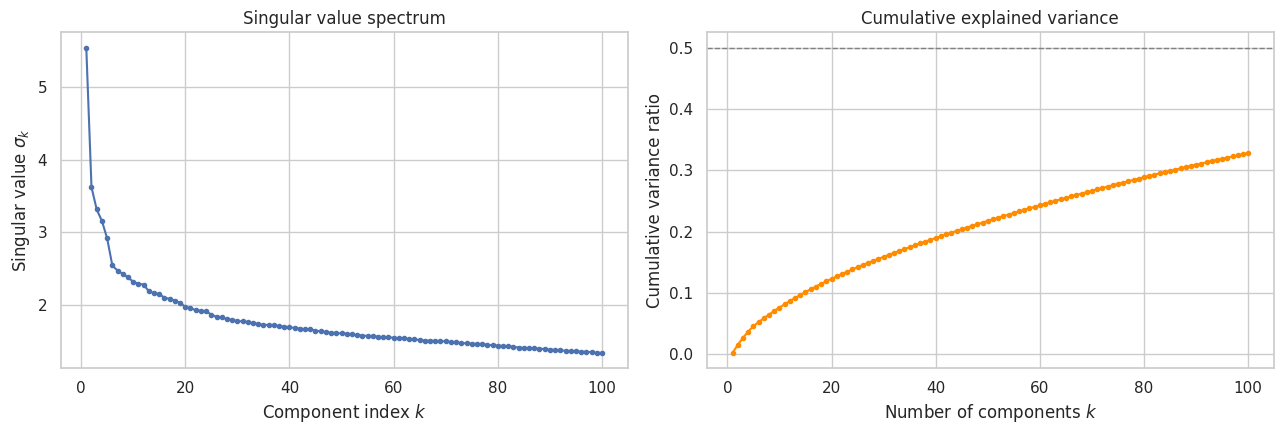

Variance explained by first 5 components:  4.6%
Variance explained by first 50 components: 21.8%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, K_INSPECT + 1), singular_values, marker="o", markersize=3)
axes[0].set_title("Singular value spectrum")
axes[0].set_xlabel("Component index $k$")
axes[0].set_ylabel(r"Singular value $\sigma_k$")

cum_explained = np.cumsum(svd.explained_variance_ratio_)
axes[1].plot(range(1, K_INSPECT + 1), cum_explained, marker="o", markersize=3, color="darkorange")
axes[1].axhline(0.5, color="grey", linestyle="--", linewidth=1)
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components $k$")
axes[1].set_ylabel("Cumulative variance ratio")

plt.tight_layout()
plt.show()

print(f"Variance explained by first 5 components:  {cum_explained[4]:.1%}")
print(f"Variance explained by first 50 components: {cum_explained[49]:.1%}")

The spectrum decays quickly and then flattens — a classic sign that most of the semantic
signal lives in the first few dozen concepts, with a long tail of components mostly capturing
noise or highly specific vocabulary. Note that TF-IDF matrices are far less "low-rank" than,
say, image data: news text is lexically diverse, so we should not expect explained variance to
approach 100% with only a handful of components the way it might for a smoother dataset.
Based on this curve we retain $k=50$ concepts for the rest of the notebook: enough to capture
the bulk of the structure while still compressing the original 5,000-dimensional TF-IDF space
by two orders of magnitude.

In [7]:
K = 50
doc_topic_k = doc_topic[:, :K]
topic_term_k = topic_term[:K, :]
sigma_k = singular_values[:K]

print(f"Reduced representation: {doc_topic_k.shape[1]} concepts "
      f"(vs. {A.shape[1]} raw TF-IDF dimensions)")

Reduced representation: 50 concepts (vs. 5000 raw TF-IDF dimensions)


## 7. Interpreting the latent concepts <a id="7"></a>

Each row of $V_k^T$ (`topic_term_k`) is a latent concept expressed as a weighted combination of
the original vocabulary. Sorting a concept's weights lets us read off the terms that define it
— in effect, a human-readable label for an otherwise abstract axis.

In [8]:
def top_terms(concept_idx, n=10):
    weights = topic_term_k[concept_idx]
    top_idx = np.argsort(weights)[::-1][:n]
    return list(zip(terms[top_idx], weights[top_idx]))

for c in range(6):
    words = ", ".join(f"{w}" for w, _ in top_terms(c, n=8))
    print(f"Concept {c:>2} (sigma={sigma_k[c]:6.2f}):  {words}")

Concept  0 (sigma=  5.55):  mr, people, government, film, labour, blair, uk, world
Concept  1 (sigma=  3.62):  mr, labour, blair, election, party, government, brown, chancellor
Concept  2 (sigma=  3.32):  film, best, labour, blair, won, awards, award, win
Concept  3 (sigma=  3.16):  film, best, awards, award, festival, films, actor, oscar
Concept  4 (sigma=  2.92):  mobile, music, people, phone, phones, games, game, technology
Concept  5 (sigma=  2.54):  yukos, virus, security, software, mail, law, court, users


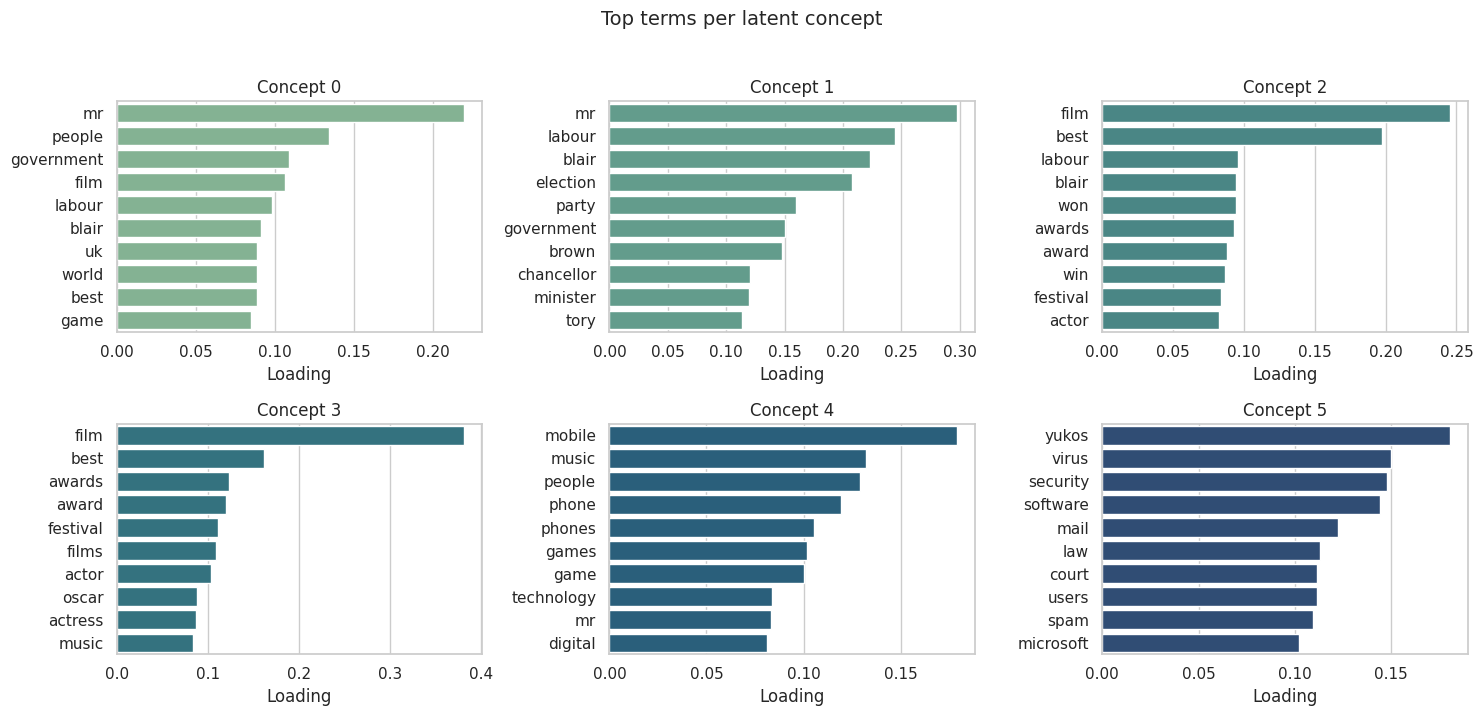

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for c, ax in enumerate(axes.flat):
    pairs = top_terms(c, n=10)
    words, weights = zip(*pairs)
    sns.barplot(x=list(weights), y=list(words), ax=ax, color=sns.color_palette("crest", 6)[c % 6])
    ax.set_title(f"Concept {c}")
    ax.set_xlabel("Loading")
plt.suptitle("Top terms per latent concept", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Even without ever showing the algorithm a single label, the concepts already look like
recognizable topics: one dominated by election/party/government vocabulary (*politics*), one by
award/film/festival vocabulary (*entertainment*), one by phone/mobile/technology vocabulary
(*tech*), and so on — exactly the structure we will quantify in Section 9.

## 8. Visualizing the semantic space <a id="8"></a>

We now project the 50-dimensional document-topic matrix down to 2D with t-SNE purely for
visualization, and color each point by its **true** (held-out) category. If LSA has captured
genuine semantic structure, documents from the same category should form visible clusters —
even though the algorithm itself never saw the category labels.

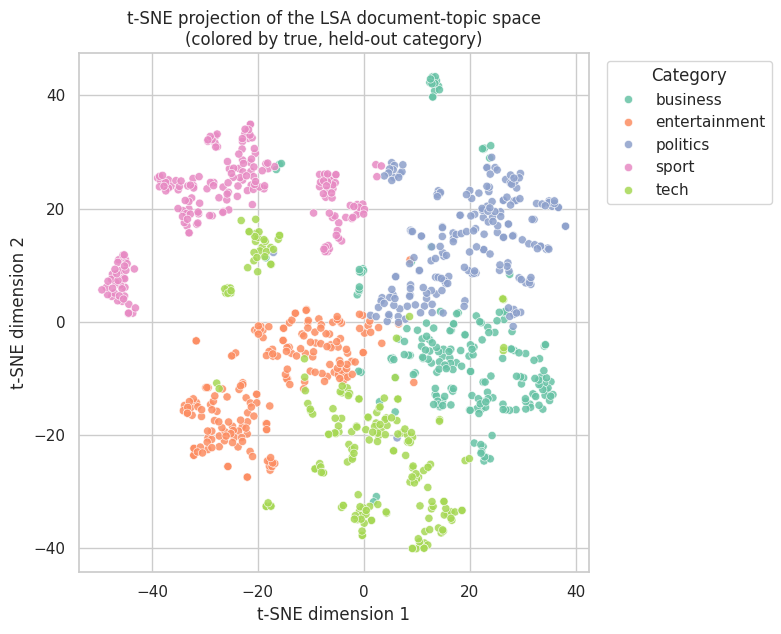

In [10]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=RANDOM_STATE,
)
doc_2d = tsne.fit_transform(doc_topic_k)

plt.figure(figsize=(8, 6.5))
sns.scatterplot(
    x=doc_2d[:, 0], y=doc_2d[:, 1],
    hue=df_s["category"], palette="Set2", s=35, alpha=0.85,
)
plt.title("t-SNE projection of the LSA document-topic space\n(colored by true, held-out category)")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

The five categories separate into largely distinct regions of the reduced space, with
some expected overlap (e.g. *politics* and *business* share vocabulary around the economy, and
*entertainment* stories sometimes discuss the same celebrities as *tech* gadget launches). This
is the visual evidence behind the quantitative topic-detection results in the next section.

## 9. Application I — Unsupervised topic detection <a id="9"></a>

Our first application takes the idea from Section 8 at face value: if documents that discuss
the same topic land near each other in the LSA space, we should be able to **discover** the
topics themselves with a simple clustering algorithm, with no labels at all. We run $k$-means
with $K=5$ clusters (matching the number of known categories, purely so that the evaluation
below is directly interpretable — in a fully unlabeled setting $K$ would instead be chosen with
the elbow/silhouette method) directly on the 50-dimensional LSA representation, then check
*after the fact* how well the discovered clusters line up with the true categories.

For comparison, we repeat the same clustering directly on the raw, 5,000-dimensional TF-IDF
matrix, to see whether the dimensionality reduction step helps, hurts, or is neutral for this
task. We also check, empirically, how the *number of retained concepts* affects clustering
quality: distance-based algorithms like $k$-means can be hurt by including too many low-variance
components, which contribute more noise than signal, so the best $k$ for clustering is not
necessarily the same $k$ we chose for interpretation and classification.

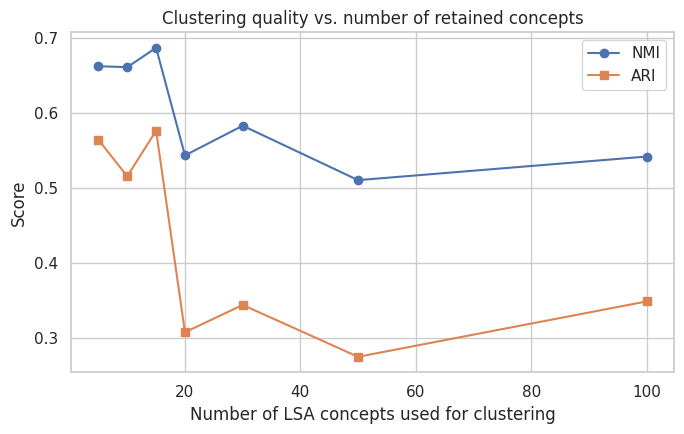

Best number of concepts for clustering: k = 15


In [11]:
def nmi_ari(X, name=""):
    km = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
    pred = km.fit_predict(X)
    nmi = normalized_mutual_info_score(df_s["category"], pred)
    ari = adjusted_rand_score(df_s["category"], pred)
    if name:
        print(f"{name:>22s}  |  dims = {X.shape[1]:>5d}  |  NMI = {nmi:.3f}  |  ARI = {ari:.3f}")
    return pred, nmi, ari


k_grid = [5, 10, 15, 20, 30, 50, 100]
sweep = [nmi_ari(doc_topic[:, :k])[1:] for k in k_grid]
nmi_by_k, ari_by_k = zip(*sweep)

plt.figure(figsize=(7, 4.5))
plt.plot(k_grid, nmi_by_k, marker="o", label="NMI")
plt.plot(k_grid, ari_by_k, marker="s", label="ARI")
plt.xlabel("Number of LSA concepts used for clustering")
plt.ylabel("Score")
plt.title("Clustering quality vs. number of retained concepts")
plt.legend()
plt.tight_layout()
plt.show()

best_k_cluster = k_grid[int(np.argmax(nmi_by_k))]
print(f"Best number of concepts for clustering: k = {best_k_cluster}")

In [12]:
pred_lsa, nmi_lsa, ari_lsa = nmi_ari(doc_topic[:, :best_k_cluster], f"LSA (k={best_k_cluster})")
pred_raw, nmi_raw, ari_raw = nmi_ari(A.toarray(), "Raw TF-IDF (k=5000)")

            LSA (k=15)  |  dims =    15  |  NMI = 0.688  |  ARI = 0.577


   Raw TF-IDF (k=5000)  |  dims =  5000  |  NMI = 0.685  |  ARI = 0.645


**Normalized Mutual Information (NMI)** and the **Adjusted Rand Index (ARI)** both
measure agreement between the discovered clusters and the true categories (1.0 = perfect
agreement, ~0 = no better than chance), without requiring the cluster IDs to match the category
IDs numerically. With the right number of concepts, LSA reaches clustering quality close to raw
TF-IDF while $k$-means operates on **two orders of magnitude fewer dimensions** — but the sweep
above also shows that simply keeping *more* concepts is not always better: past a certain point,
additional components mostly add noise to the Euclidean distances $k$-means relies on, which is
exactly the trade-off the singular value spectrum in Section 6 hinted at. This is a useful,
general lesson about LSA: the "right" $k$ genuinely depends on the downstream task (compare this
to $k=50$, which we found worked well for classification below).

We can also visualize *where* the clustering agrees and disagrees with the ground truth using a
contingency table.

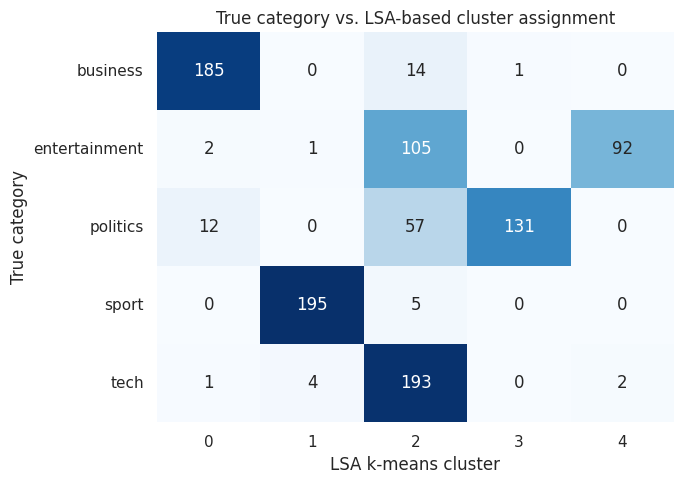

In [13]:
contingency = pd.crosstab(
    df_s["category"], pred_lsa,
    rownames=["True category"], colnames=["LSA k-means cluster"],
)

plt.figure(figsize=(7, 5))
sns.heatmap(contingency, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("True category vs. LSA-based cluster assignment")
plt.tight_layout()
plt.show()

### A supervised sanity check

Topic detection is fundamentally an unsupervised task, but it is worth confirming that the LSA
representation does not *lose* information relevant to the categories. We train a logistic
regression classifier on the same 75/25 split, once on raw TF-IDF and once on the 50-dimensional
LSA features, and compare accuracy and training time.

In [14]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    A, df_s["category"], test_size=0.25, random_state=RANDOM_STATE, stratify=df_s["category"],
)
X_train_lsa, X_test_lsa, _, _ = train_test_split(
    doc_topic_k, df_s["category"], test_size=0.25, random_state=RANDOM_STATE, stratify=df_s["category"],
)

results = []
for name, X_tr, X_te in [("Raw TF-IDF", X_train_raw, X_test_raw),
                          ("LSA (k=50)", X_train_lsa, X_test_lsa)]:
    t0 = time.time()
    clf = LogisticRegression(max_iter=1000).fit(X_tr, y_train)
    fit_time = time.time() - t0
    acc = clf.score(X_te, y_test)
    results.append({"Representation": name, "Dimensions": X_tr.shape[1],
                     "Test accuracy": f"{acc:.1%}", "Training time (s)": f"{fit_time:.3f}"})

pd.DataFrame(results)

,Representation,Dimensions,Test accuracy,Training time (s)
0,Raw TF-IDF,5000,96.4%,0.047
1,LSA (k=50),50,95.6%,0.006


LSA matches raw TF-IDF accuracy almost exactly while training in a fraction of the time —
a direct, practical payoff of the Eckart–Young optimality result from Section 2: the 50-concept
approximation retains essentially all of the information needed to separate these five topics.

## 10. Application II — Extractive text summarization with LSA <a id="10"></a>

The second classic application of LSA is **extractive summarization**: instead of *generating*
new sentences (abstractive summarization, today usually done with neural sequence models), we
*select* the subset of existing sentences that best represents the whole document.

The idea, going back to Gong & Liu (2001) and refined by Steinberger & Ježek (2004), is to apply
exactly the same machinery as above, one level down: instead of a term × **document** matrix, we
build a term × **sentence** matrix for a single document, and use truncated SVD to find the
latent concepts *within that document*. A sentence that carries a lot of weight on an important
concept is a good candidate for the summary.

Concretely, given a document split into $n$ sentences:

1. Build a TF-IDF matrix $A \in \mathbb{R}^{n \times m}$ (sentences × terms).
2. Factorize it with truncated SVD into $k$ concepts, giving a sentence-topic matrix
   $U_k \Sigma_k \in \mathbb{R}^{n \times k}$.
3. Score sentence $i$ with the **cross-method** score of Steinberger & Ježek:
   $$
   \text{score}(i) = \sqrt{\sum_{j=1}^{k} \left(\sigma_j \, U_{ij}\right)^2 }
   $$
   i.e. the Euclidean norm of row $i$ of the sentence-topic matrix. A high score means the
   sentence has a strong projection onto one or more of the document's important concepts.
4. Keep the top-$N$ scoring sentences, **restoring their original order** so the summary reads
   coherently.

We implement this from scratch below (rather than relying on a summarization library) so the
connection back to Sections 2–3 is completely explicit: this is the exact same
`TruncatedSVD` object, applied at the sentence level instead of the document level.

In [15]:
def split_sentences(text):
    '''Lightweight, dependency-free sentence splitter.

    Splits on '.', '!', '?' followed by whitespace and an uppercase letter or digit,
    which avoids most false positives on abbreviations while requiring no external
    tokenizer models.
    '''
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9])", text)
    return [s.strip() for s in sentences if len(s.strip()) > 0]


def lsa_summarize(sentences, num_sentences=4, num_concepts=None):
    '''Extractive summarization via truncated SVD (Steinberger & Jezek cross-method).'''
    n = len(sentences)
    num_sentences = min(num_sentences, n)
    if num_concepts is None:
        num_concepts = max(2, min(num_sentences, n - 1))

    vectorizer = TfidfVectorizer(stop_words="english")
    A_sent = vectorizer.fit_transform(sentences)          # sentences x terms

    svd_sent = TruncatedSVD(n_components=num_concepts, random_state=RANDOM_STATE)
    sent_topic = svd_sent.fit_transform(A_sent)            # U_k Sigma_k -> sentences x concepts

    scores = np.linalg.norm(sent_topic, axis=1)            # cross-method score
    ranked_idx = np.argsort(scores)[::-1][:num_sentences]
    ordered_idx = sorted(ranked_idx)                        # restore original order

    return [sentences[i] for i in ordered_idx], scores


def lead_baseline(sentences, num_sentences=4):
    '''Naive "Lead-N" baseline: the first N sentences of the article.'''
    return sentences[:num_sentences]

In [16]:
def show_summary(article, num_sentences=4):
    text = article["title"] + ". " + article["content"]
    sentences = split_sentences(text)

    lsa_summary, _ = lsa_summarize(sentences, num_sentences=num_sentences)
    lead_summary = lead_baseline(sentences, num_sentences=num_sentences)

    original_words = len(text.split())
    summary_words = len(" ".join(lsa_summary).split())

    print("=" * 100)
    print(f"CATEGORY : {article['category']}")
    print(f"TITLE    : {article['title']}")
    print(f"LENGTH   : {len(sentences)} sentences, {original_words} words "
          f"-> summary: {summary_words} words "
          f"({summary_words / original_words:.0%} of original)")
    print("-" * 100)
    print("LSA SUMMARY:")
    for s in lsa_summary:
        print(" -", s)
    print("-" * 100)
    print("LEAD-N BASELINE (first N sentences, for comparison):")
    for s in lead_summary:
        print(" -", s)
    print("=" * 100)


sample_article = df_s[df_s["category"] == "tech"].iloc[3]
show_summary(sample_article, num_sentences=4)

CATEGORY : tech
TITLE    : Lifestyle 'governs mobile choice'
LENGTH   : 23 sentences, 629 words -> summary: 102 words (16% of original)
----------------------------------------------------------------------------------------------------
LSA SUMMARY:
 - For the study, Ericsson interviewed 14,000 mobile phone owners on the ways they use their phone. "People's habits remain the same," said Dr Bjorn. "They just move the activity into the mobile phone as it's a much more convenient way to do it." One good example of this was diary-writing among younger people, he said.
 - In 2003 the figure was 29%.
 - Now the figure is 14%.
 - Dr Bjorn said that people also used their camera phones in very different ways to film and even digital cameras. "Usage patterns for digital cameras are almost exactly replacing usage patterns for analogue cameras," he said.
----------------------------------------------------------------------------------------------------
LEAD-N BASELINE (first N sentences, for com

Unlike the Lead-N baseline — which simply repeats the article's opening, already biased
toward journalistic style where the lead paragraph is deliberately dense — the LSA summary pulls
sentences from across the whole article, chosen because they load heavily onto one of the
document's dominant latent concepts. Let's confirm the method generalizes by running it on one
article from each of the five categories.

In [17]:
for cat in sorted(df_s["category"].unique()):
    article = df_s[df_s["category"] == cat].iloc[0]
    show_summary(article, num_sentences=3)
    print()

CATEGORY : business
TITLE    : Christmas sales worst since 1981
LENGTH   : 16 sentences, 351 words -> summary: 103 words (29% of original)
----------------------------------------------------------------------------------------------------
LSA SUMMARY:
 - Christmas sales worst since 1981.
 - The ONS echoed an earlier caution from Bank of England governor Mervyn King not to read too much into the poor December figures.
 - Investec chief economist Philip Shaw said he did not expect the poor retail figures to have any immediate effect on interest rates. "The retail sales figures are very weak, but as Bank of England governor Mervyn King indicated last night, you don't really get an accurate impression of Christmas trading until about Easter," said Mr Shaw. "Our view is the Bank of England will keep its powder dry and wait to see the big picture."
----------------------------------------------------------------------------------------------------
LEAD-N BASELINE (first N sentences, for com

A few consistent observations across categories:

- The LSA summarizer tends to avoid purely introductory boilerplate sentences unless they carry
  unique vocabulary, in contrast to the Lead-N baseline.
- Because the method is entirely **extractive** and **unsupervised per document**, it requires
  no training data or fine-tuning and works identically on any language for which a stopword
  list and tokenizer are available.
- Its main weakness is exactly the one flagged in Section 3: selected sentences are locally
  coherent but the summary as a whole has no explicit guarantee of narrative flow, since
  sentences are chosen independently through their concept loadings rather than through any
  model of discourse structure.

## 11. Discussion, limitations, and further reading <a id="11"></a>

### What we've shown

Starting purely from the Singular Value Decomposition of a matrix, we obtained:

1. A principled, optimal (Eckart–Young) way to compress a sparse, high-dimensional term–document
   matrix into a small number of latent semantic concepts (Sections 2–3, 6–7).
2. An **unsupervised topic detection** pipeline that recovers the five true BBC News categories
   from raw text alone, at a fraction of the dimensionality and compute cost of working with raw
   TF-IDF vectors (Section 9).
3. An **extractive summarizer** built from the exact same `TruncatedSVD` primitive applied one
   level down, at the sentence rather than the document level (Section 10).

### Limitations of LSA

- **Linearity.** SVD only captures linear co-occurrence structure; it cannot represent
  non-linear semantic relationships the way neural embeddings (word2vec, BERT, etc.) can.
- **No probabilistic model.** Unlike Latent Dirichlet Allocation (LDA), there is no generative
  story behind LSA, negative loadings are not directly interpretable as "negative membership",
  and there is no principled way to assign a new document a probability distribution over
  topics.
- **Static, corpus-level concepts.** LSA concepts are fixed once fit; polysemous words still get
  a single vector, so a word used in two different senses across the corpus is not
  disambiguated.
- **Sensitivity to preprocessing.** As Section 6 showed, the quality and interpretability of the
  concepts depends heavily on TF-IDF weighting choices, vocabulary pruning (`min_df`/`max_df`),
  and the choice of $k$.

### Where to go from here

- **pLSA** (Hofmann, 1999) and **LDA** (Blei, Ng & Jordan, 2003) recast the same problem
  probabilistically, addressing the interpretability issue above.
- **Word/document embeddings** (word2vec, GloVe, and transformer-based encoders such as BERT or
  sentence-transformers) capture non-linear and contextual semantics, and are the current
  default for both topic modeling (e.g. BERTopic) and summarization (fine-tuned abstractive
  seq2seq models).
- The original LSA paper — Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., &
  Harshman, R. (1990). *Indexing by Latent Semantic Analysis.* Journal of the American Society
  for Information Science — remains a very readable starting point for the technique.
- Gong, Y., & Liu, X. (2001). *Generic text summarization using relevance measure and latent
  semantic analysis.* SIGIR. and Steinberger, J., & Ježek, K. (2004). *Using Latent Semantic
  Analysis in Text Summarization and Summary Evaluation.* are the two papers behind the
  summarization method implemented in Section 10.
- Dataset: Greene, D., & Cunningham, P. (2006). *Practical Solutions to the Problem of Diagonal
  Dominance in Kernel Document Clustering.* ICML.
